# Embedded 3D geometry widget

Inspect resolved geometry directly inside JupyterLab and VS Code, including when the kernel runs on another machine.

This is an executable lesson about representing building-stock diversity with EPSM Core. All dimensions are metric. The materials, use patterns and stock weights are explicit demonstration assumptions, not calibrated national statistics. Read each explanation before changing the code.

**How to use:** select the **EPSM Core Demo** kernel and Run All from a fresh kernel. Each notebook is independent; generated files go under `output/demo/`. Setup instructions and the complete learning path are in [the demo guide](../README.md).

**Prerequisites:** notebook environment; no EnergyPlus or weather required.

## Understanding the API in this lesson

`GeometrySpec.widget(...)` returns a `GeometryWidget`, and `BuildingSpec.widget(...)` supplies that building's facade and context. `display(widget)` creates a notebook view. The scene is based on the same resolved geometry as the standalone viewer, but does not require a browser to contact a loopback server on the kernel machine.

The screenshot below is an orientation guide to the existing controls, not a live instance and not this notebook's U-shaped model. Use the live output to orbit, isolate storeys, inspect surfaces and change cutaway. Use the static image to understand the intended geometry in a non-executing notebook reader.

### Figure guide — Existing viewer controls and target/context separation

![Existing viewer controls and target/context separation; reference figure from EPSM documentation](../../docs/figures/viewer-controls.png)

**How to read this figure.** Use Focus building and Fit context to change framing; use storey isolation and cutaway to inspect the target. Grey neighbours retain their complete silhouettes. This documentation screenshot shows a 30 × 20 m, three-storey target with 25 synthetic high-rise neighbours; it is not a live widget or a simulation result from this notebook.

*Source: [EPSM usage documentation](../../docs/usage.md); [open the original figure](../../docs/figures/viewer-controls.png).*

### Before the first code cell

The setup cell finds the repository, imports the package and plotting tools, and creates a fresh `OUT` directory. `building()` and `geometry()` are **demo input factories**; `table()`, `plans()`, `bars()` and `preview()` are **presentation helpers**, not public `epsm_core` entry points. In particular, `preview()` already displays its output and returns no handle, avoiding duplicate widget display. The public specification and simulation calls remain visible in the lesson cells. Run the setup once per fresh kernel, then follow the cells in order.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/epsm_core").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import json
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from epsm_core import *
from demo.support.common import (building, geometry, epw, engine, workspace, table,
                                 plans, preview, bars, weather_frame, result_frame, result_plots)
from epsm_core.inspection import geometry_scene
OUT = workspace(Path.cwd().name)


## Display an engine-independent scene

The widget receives bundled JavaScript and scene data through the kernel. It does not depend on a browser reaching the kernel machine through localhost.

### Read the code and output

The MIME assertion checks that Python produced a widget view descriptor. It cannot prove that WebGL actually rendered in the notebook frontend. The scene equality check later connects the payload to the shared geometry representation. A static image can remain readable even when no kernel is running.

Reference: [How geometry feeds compilation, physical quantities and inspection](../../docs/figures/geometry-pipeline.svg). This linked documentation illustration is separate from the outputs computed below.

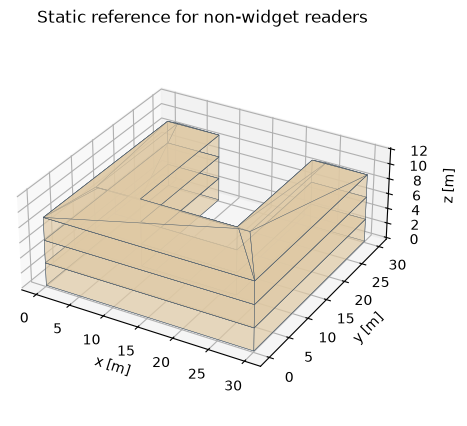

In [2]:
from epsm_core.notebook import GeometryWidget
from epsm_core.viewer import viewer_data
g=geometry(Footprint.u_shape(30,30,14,20),roof=RoofSpec(shape="hip"))
widget=g.widget(height=600)
assert isinstance(widget,GeometryWidget)
assert widget._repr_mimebundle_()[0]["application/vnd.jupyter.widget-view+json"]["model_id"]
display(widget)
preview(g,"Static reference for non-widget readers",interactive=False)

## Use inspection controls

Drag to orbit, scroll to zoom, choose a storey and enable cutaway. Select a surface using the dropdown or by clicking the geometry; the next cell reads the Python selection state.

### Read the code and output

Choose a surface in the widget, then rerun the selection-reading cell to inspect `selected_surface` in Python. An empty string before selection is expected. Names and available metadata describe resolved surfaces; geometry-only scenes have no thermal construction assignments to inspect.

In [3]:
print("Selected surface (empty until you select one):",widget.selected_surface)
scene,report=geometry_scene(g)
assert widget.scene==viewer_data(scene,report)
table({"objects":len(widget.scene["objects"]),"geometry_only":widget.scene["report"]["geometry_only"],"height_px":widget.height})

Selected surface (empty until you select one): 


,field,value
0,objects,49
1,geometry_only,True
2,height_px,600


,field,value
0,objects,49
1,geometry_only,True
2,height_px,600


## Manage widget lifetime

Changing height updates the existing view. close releases the frontend when you are finished; do not close the visible widget immediately after displaying it.

### Read the code and output

Changing `height` updates the existing widget view. Closing a handle releases its live frontend resources, so do not close the visible example until you finish inspection. Multiple displays of one handle are views of the same widget model; create separate widgets when you want independent selection state.

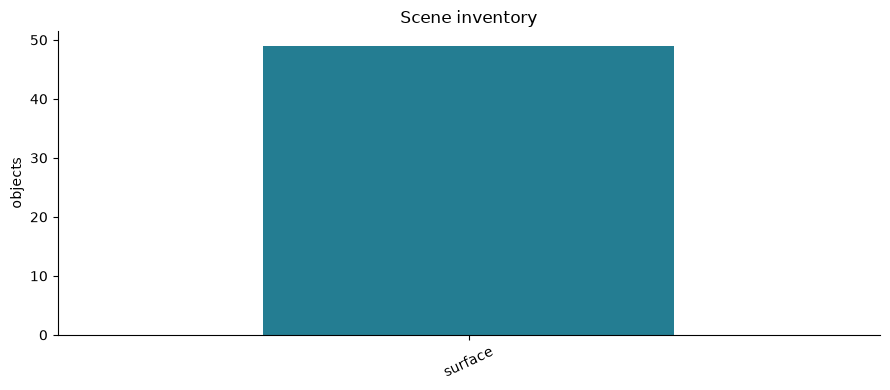

In [4]:
widget.height=650
probe=g.widget(height=250)
probe.close()  # An undisplayed probe verifies explicit lifecycle use.
bars({kind:sum(o["kind"]==kind for o in widget.scene["objects"]) for kind in {o["kind"] for o in widget.scene["objects"]}},"objects","Scene inventory")
# When finished inspecting the visible widget, run: widget.close()

## Interpretation and next experiment

A static notebook preview cannot execute WebGL. Rerun the display cell in a trusted live notebook to activate the embedded controls.

For a stock study, retain the inputs, provenance and acceptance decisions with every result. A successful geometry preview does not establish simulation validity or predictive accuracy. Change one assumption at a time before combining measures, and report rejected or substituted cases alongside accepted cases.